<a href="https://colab.research.google.com/github/dash0k00/ML2026/blob/main/lab3_rock_music_generation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №3. Генерация рок-музыки с помощью RNN

Построить на базе рекуррентной нейронной сети модель, генерирующую рок-музыку. В качестве обучающей выборки используется датасет `Music.Popular.Rock.MIDI`.

Музыкальная партия представляется как последовательность нот, где каждая нота описывается тремя числами:

* `pitch` — высота ноты (номер MIDI, 0–127);
* `step` — время от начала предыдущей ноты до начала текущей (в секундах);
* `duration` — длительность звучания ноты (в секундах).


##Подготовка окружения

In [1]:
!sudo apt install -y fluidsynth
!pip install --upgrade pyfluidsynth
!pip install pretty_midi

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core fluid-soundfont-gm gsettings-desktop-schemas
  libatk-bridge2.0-0t64 libatk1.0-0t64 libatspi2.0-0t64 libb2-1
  libdouble-conversion3 libevdev2 libfluidsynth3 libgtk-3-0t64 libgtk-3-bin
  libgtk-3-common libgudev-1.0-0 libinput-bin libinput10 libinstpatch-1.0-2
  libmd4c0 libmtdev1t64 libpipewire-0.3-0t64 libpipewire-0.3-common
  libproxy1v5 libqt6core6t64 libqt6dbus6t64 libqt6gui6t64 libqt6network6t64
  libqt6opengl6t64 libqt6qml6 libqt6qmlmodels6 libqt6quick6
  libqt6waylandclient6 libqt6waylandcompositor6
  libqt6waylandeglclienthwintegration6
  libqt6waylandeglcompositorhwintegration6 libqt6widgets6t64
  libqt6wlshellintegration6 librsvg2-common libspa-0.2-modules libts0t64
  libwacom-common libwacom9 libwayland-server0 libwebrtc-audio-processing1
  libxcb-icccm4 libxcb-image0 libxcb-keysyms1 libxcb-render

In [2]:
import collections
import glob
import pathlib
import random

import fluidsynth
import numpy as np
import pandas as pd
import pretty_midi
import seaborn as sns
import tensorflow as tf

from IPython import display
from matplotlib import pyplot as plt
from typing import Optional

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

# частота дискретизации для прослушивания в ноутбуке
_SAMPLING_RATE = 16000

## Загрузка датасета

Используется датасет Music.Popular.Rock.MIDI — набор MIDI-файлов рок-композиций

In [3]:
DATA_DIR = pathlib.Path('data/rock_midi')

if not DATA_DIR.exists() or not any(DATA_DIR.rglob('*.mid*')):
    DATA_DIR.mkdir(parents=True, exist_ok=True)

    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        !unzip -q -o "{name}" -d {DATA_DIR}


Saving 5436031.zip to 5436031.zip


In [4]:
filenames = sorted(
    glob.glob(str(DATA_DIR / '**/*.mid'), recursive=True) +
    glob.glob(str(DATA_DIR / '**/*.midi'), recursive=True) +
    glob.glob(str(DATA_DIR / '**/*.MID'), recursive=True)
)
print('Количество MIDI-файлов:', len(filenames))

Количество MIDI-файлов: 25


## Работа с MIDI-файлами

In [5]:
GUITAR_PROGRAMS = set(range(24, 32))
MIN_NOTES = 200                        #короткие дорожки отбрасываем


def pick_track(pm: pretty_midi.PrettyMIDI, programs=GUITAR_PROGRAMS):

    candidates = [ins for ins in pm.instruments
                  if not ins.is_drum and ins.program in programs and len(ins.notes) > 0]
    if not candidates:
        return None
    return max(candidates, key=lambda ins: len(ins.notes)) #возвращает дорожку с гитарой, у которой больше всего нот (или None)


def midi_to_notes(midi_file: str, programs=GUITAR_PROGRAMS) -> Optional[pd.DataFrame]:

    try:
        pm = pretty_midi.PrettyMIDI(midi_file)
    except Exception:
        return None                      #битый файл

    instrument = pick_track(pm, programs)
    if instrument is None:
        return None

    #сортируем по времени начала, а при равенстве — по высоте аккордов
    sorted_notes = sorted(instrument.notes, key=lambda n: (n.start, n.pitch))
    if len(sorted_notes) < MIN_NOTES:
        return None

    notes = collections.defaultdict(list)
    prev_start = sorted_notes[0].start
    for note in sorted_notes:
        notes['pitch'].append(note.pitch)
        notes['start'].append(note.start)
        notes['end'].append(note.end)
        notes['step'].append(note.start - prev_start)
        notes['duration'].append(note.end - note.start)
        prev_start = note.start

    return pd.DataFrame({k: np.array(v) for k, v in notes.items()})


def display_audio(pm: pretty_midi.PrettyMIDI, seconds=30):
    waveform = pm.fluidsynth(fs=_SAMPLING_RATE)
    #берём только начало, чтобы не перегружать ядро
    waveform_short = waveform[:seconds * _SAMPLING_RATE]
    return display.Audio(waveform_short, rate=_SAMPLING_RATE)


def plot_piano_roll(notes: pd.DataFrame, count: Optional[int] = None, title_prefix=''):
    if count:
        title = f'{title_prefix}первые {count} нот'
    else:
        title = f'{title_prefix}весь трек'
        count = len(notes['pitch'])
    plt.figure(figsize=(20, 4))
    plot_pitch = np.stack([notes['pitch'], notes['pitch']], axis=0)
    plot_start_stop = np.stack([notes['start'], notes['end']], axis=0)
    plt.plot(plot_start_stop[:, :count], plot_pitch[:, :count], color='b', marker='.')
    plt.xlabel('Время, с')
    plt.ylabel('Высота ноты (pitch)')
    plt.title(title)
    plt.show()


def plot_distributions(notes: pd.DataFrame, drop_percentile=2.5):
    plt.figure(figsize=[15, 5])
    plt.subplot(1, 3, 1)
    sns.histplot(notes, x='pitch', bins=20)

    plt.subplot(1, 3, 2)
    max_step = np.percentile(notes['step'], 100 - drop_percentile)
    sns.histplot(notes, x='step', bins=np.linspace(0, max_step, 21))

    plt.subplot(1, 3, 3)
    max_duration = np.percentile(notes['duration'], 100 - drop_percentile)
    sns.histplot(notes, x='duration', bins=np.linspace(0, max_duration, 21))
    plt.show()


def notes_to_midi(notes: pd.DataFrame, out_file: str, program: int = 30,
                  velocity: int = 100, add_drums: bool = False, bpm: float = 120.0):

    pm = pretty_midi.PrettyMIDI(initial_tempo=bpm)
    guitar = pretty_midi.Instrument(program=program, name='Generated guitar') #собирает MIDI-файл из таблицы нот

    prev_start = 0.0
    for _, row in notes.iterrows():
        start = float(prev_start + row['step'])
        end = float(start + max(row['duration'], 0.05))
        guitar.notes.append(pretty_midi.Note(
            velocity=velocity, pitch=int(row['pitch']), start=start, end=end))
        prev_start = start
    pm.instruments.append(guitar)

    if add_drums:
        pm.instruments.append(make_rock_drums(total_time=prev_start + 2.0, bpm=bpm))

    pm.write(out_file)
    return pm


def make_rock_drums(total_time: float, bpm: float = 120.0) -> pretty_midi.Instrument:

    KICK, SNARE, HIHAT = 36, 38, 42 #простой рок-бит 4/4
    drums = pretty_midi.Instrument(program=0, is_drum=True, name='Rock drums')
    beat = 60.0 / bpm
    t, i = 0.0, 0
    while t < total_time:
        pos = i % 4                                  #доля в такте
        if pos in (0, 2):
            drums.notes.append(pretty_midi.Note(110, KICK, t, t + 0.1))
        if pos in (1, 3):
            drums.notes.append(pretty_midi.Note(105, SNARE, t, t + 0.1))
        drums.notes.append(pretty_midi.Note(80, HIHAT, t, t + 0.05))
        drums.notes.append(pretty_midi.Note(65, HIHAT, t + beat / 2, t + beat / 2 + 0.05))
        t += beat
        i += 1
    return drums

### Изучаем данные

In [6]:
sample_file, raw_notes = None, None
for f in filenames:
    raw_notes = midi_to_notes(f)
    if raw_notes is not None:
        sample_file = f
        break

print('Файл:', sample_file)
pm = pretty_midi.PrettyMIDI(sample_file)
print('Дорожки в файле:')
for ins in pm.instruments:
    name = 'ударные' if ins.is_drum else pretty_midi.program_to_instrument_name(ins.program)
    print(f'  - {name}: {len(ins.notes)} нот')
raw_notes.head()

Файл: data/rock_midi/EricClapton.Born_Under_a_Bad_Sign.mid
Дорожки в файле:
  - Alto Sax: 237 нот
  - Rock Organ: 1081 нот
  - Brass Section: 638 нот
  - Electric Bass (finger): 236 нот
  - Distortion Guitar: 519 нот
  - Overdriven Guitar: 38 нот
  - Baritone Sax: 77 нот
  - ударные: 387 нот
  - ударные: 221 нот
  - ударные: 531 нот
  - ударные: 2 нот
  - ударные: 183 нот
  - ударные: 15 нот
  - ударные: 5 нот
  - ударные: 7 нот


,pitch,start,end,step,duration
0,70,2.222224,3.043984,0.000000,0.821760
1,63,3.055558,3.335651,0.833334,0.280093
2,65,3.333336,3.613429,0.277778,0.280093
3,68,3.611114,3.900466,0.277778,0.289352
4,70,3.888892,4.145837,0.277778,0.256945


In [7]:
display_audio(pm)

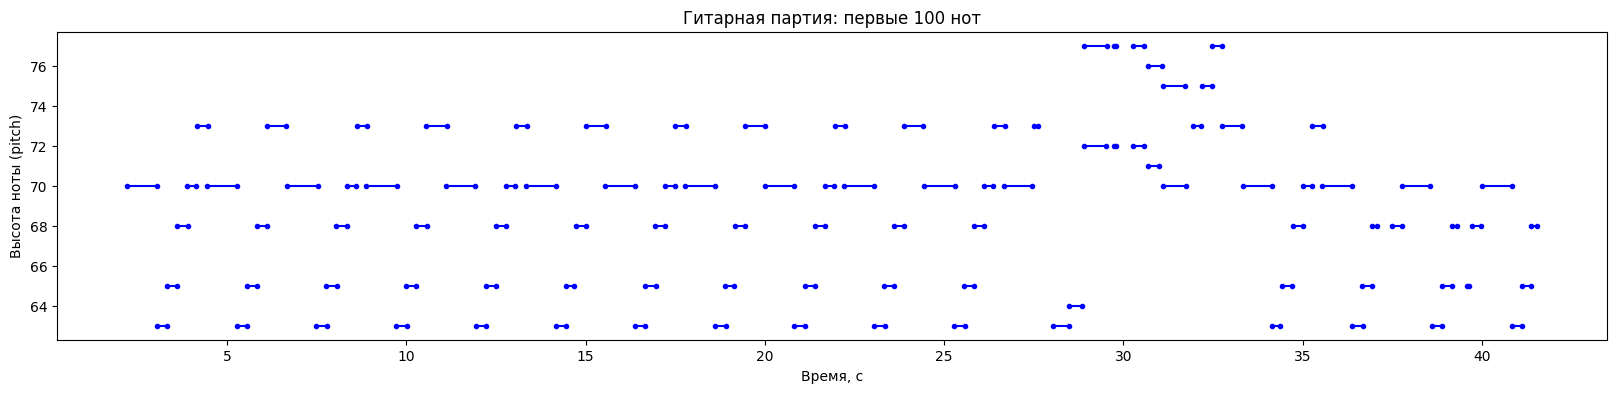

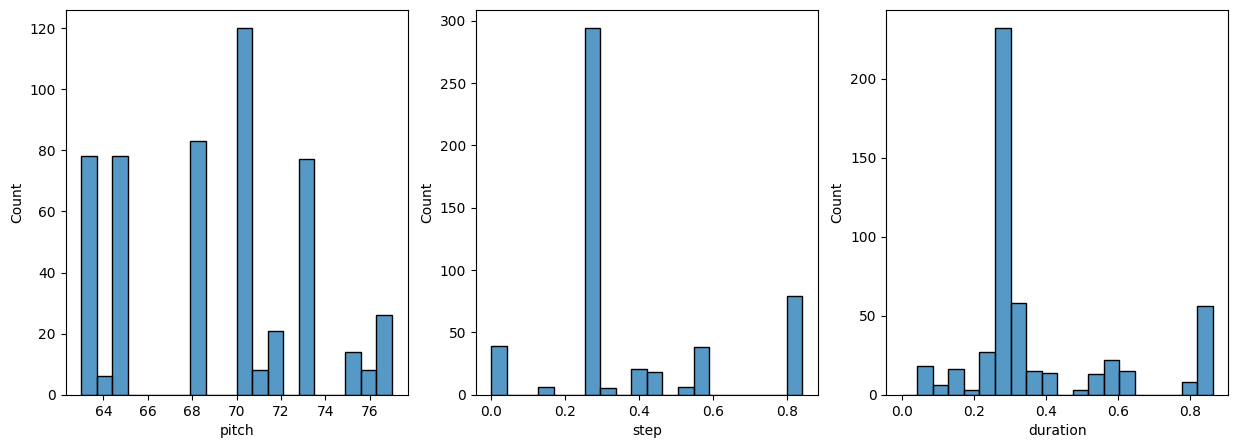

In [8]:
plot_piano_roll(raw_notes, count=100, title_prefix='Гитарная партия: ')
plot_distributions(raw_notes)

## Подготовка обучающей выборки


In [9]:
MAX_FILES = 300          #сколько файлов использовать
MAX_NOTES_PER_FILE = 3000
CLIP_TIME = 2.0          #секунд: верхняя граница step и duration

random.shuffle(filenames)
parsed = []              #список (имя файла, DataFrame)
for f in filenames:
    if len(parsed) >= MAX_FILES:
        break
    df = midi_to_notes(f)
    if df is None:
        continue
    df = df.iloc[:MAX_NOTES_PER_FILE].copy()
    df['step'] = df['step'].clip(0, CLIP_TIME)
    df['duration'] = df['duration'].clip(0, CLIP_TIME)
    parsed.append((f, df))

print('Файлов с гитарной партией:', len(parsed))
print('Всего нот:', sum(len(d) for _, d in parsed))

/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


Файлов с гитарной партией: 19
Всего нот: 17470


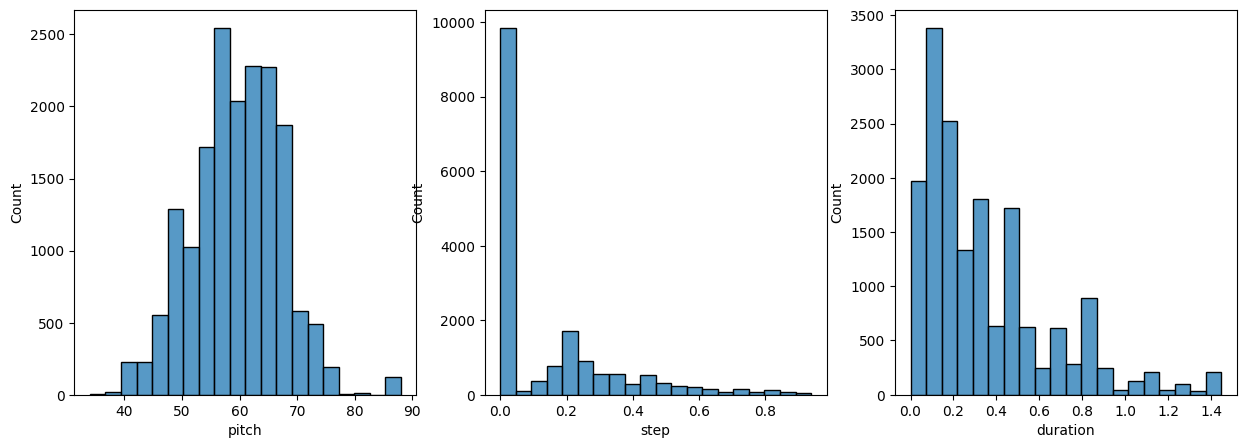

              pitch          step      duration
count  17470.000000  17470.000000  17470.000000
mean      59.547338      0.174961      0.386728
std        7.748702      0.297087      0.385229
min       34.000000      0.000000      0.004464
25%       55.000000      0.000000      0.130208
50%       60.000000      0.004167      0.266204
75%       65.000000      0.260870      0.495833
max       88.000000      2.000000      2.000000


In [10]:
all_notes_df = pd.concat([d for _, d in parsed])
plot_distributions(all_notes_df)
print(all_notes_df[['pitch', 'step', 'duration']].describe())

In [11]:
key_order = ['pitch', 'step', 'duration']
seq_length = 50
vocab_size = 128


def make_windows(df: pd.DataFrame, seq_length: int, stride: int = 2):
    """Нарезает один трек на окна: X — seq_length нот, y — следующая нота."""
    arr = df[key_order].to_numpy(dtype=np.float32)
    if len(arr) <= seq_length:
        return None, None
    win = np.lib.stride_tricks.sliding_window_view(arr, (seq_length + 1, 3))[:, 0]
    win = win[::stride]
    X = win[:, :-1, :].copy()
    y = win[:, -1, :].copy()
    X[:, :, 0] /= vocab_size             #нормализуем pitch
    return X, y


#делим на train/val по ФАЙЛАМ (80/20)
n_val = max(1, int(0.2 * len(parsed)))
val_files, train_files = parsed[:n_val], parsed[n_val:]


def build(files):
    Xs, ys = [], []
    for _, df in files:
        X, y = make_windows(df, seq_length)
        if X is not None:
            Xs.append(X)
            ys.append(y)
    X, y = np.concatenate(Xs), np.concatenate(ys)
    labels = {'pitch': y[:, 0].astype(np.int32),
              'step': y[:, 1],
              'duration': y[:, 2]}
    return X, labels


X_train, y_train = build(train_files)
X_val, y_val = build(val_files)
print('Обучающая выборка:', X_train.shape, 'валидационная:', X_val.shape)

Обучающая выборка: (7026, 50, 3) валидационная: (1240, 50, 3)


## Модель

In [12]:
def mse_with_positive_pressure(y_true: tf.Tensor, y_pred: tf.Tensor):
    mse = (y_true - y_pred) ** 2
    positive_pressure = 10 * tf.maximum(-y_pred, 0.0)
    return tf.reduce_mean(mse + positive_pressure)


def build_model(seq_length: int, learning_rate: float = 0.003) -> tf.keras.Model:
    inputs = tf.keras.Input((seq_length, 3))
    x = tf.keras.layers.LSTM(256, return_sequences=True)(inputs)
    x = tf.keras.layers.Dropout(0.2)(x)
    x = tf.keras.layers.LSTM(128)(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    outputs = {
        'pitch': tf.keras.layers.Dense(128, name='pitch')(x),
        'step': tf.keras.layers.Dense(1, name='step')(x),
        'duration': tf.keras.layers.Dense(1, name='duration')(x),
    }
    model = tf.keras.Model(inputs, outputs)

    model.compile(
        loss={
            'pitch': tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            'step': mse_with_positive_pressure,
            'duration': mse_with_positive_pressure,
        },
        loss_weights={'pitch': 0.05, 'step': 1.0, 'duration': 1.0},
        metrics={'pitch': 'sparse_categorical_accuracy'},
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    )
    return model


model = build_model(seq_length)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 50, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 50, 256)   │    266,240 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 50, 256)   │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 128)       │    197,120 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration (Dense)    │ (None, 1)         │        129 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pitch (Dense)       │ (None, 128)       │     16,512 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ step (Dense)        │ (None, 1)         │        129 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 480,130 (1.83 MB)

 Trainable params: 480,130 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
#значения функций потерь до обучения
print(model.evaluate(X_val, y_val, batch_size=128, return_dict=True, verbose=0))

{'duration_loss': 0.2651475965976715, 'loss': 0.588711678981781, 'pitch_loss': 4.851286888122559, 'pitch_sparse_categorical_accuracy': 0.0, 'step_loss': 0.0845399871468544}


##обучение

In [14]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='best_rock_model.weights.h5',
        monitor='val_loss', save_best_only=True, save_weights_only=True),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, verbose=1),
]

epochs = 50
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=128,
    callbacks=callbacks,
)

Epoch 1/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 41s 661ms/step - duration_loss: 0.1146 - loss: 0.4337 - pitch_loss: 4.3996 - pitch_sparse_categorical_accuracy: 0.0714 - step_loss: 0.0990 - val_duration_loss: 0.0563 - val_loss: 0.3124 - val_pitch_loss: 4.0594 - val_pitch_sparse_categorical_accuracy: 0.0347 - val_step_loss: 0.0577 - learning_rate: 0.0030
Epoch 2/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 49s 810ms/step - duration_loss: 0.0919 - loss: 0.3456 - pitch_loss: 3.3476 - pitch_sparse_categorical_accuracy: 0.0981 - step_loss: 0.0864 - val_duration_loss: 0.0479 - val_loss: 0.3063 - val_pitch_loss: 4.0341 - val_pitch_sparse_categorical_accuracy: 0.0629 - val_step_loss: 0.0600 - learning_rate: 0.0030
Epoch 3/50
55/55 ━━━━━━━━━━━━━━━━━━━━ 74s 660ms/step - duration_loss: 0.0858 - loss: 0.3369 - pitch_loss: 3.2627 - pitch_sparse_categorical_accuracy: 0.1011 - step_loss: 0.0880 - val_duration_loss: 0.0474 - val_loss: 0.3081 - val_pitch_loss: 4.1174 - val_pitch_sparse_categorical_accuracy: 0.0379 - val_step_lo

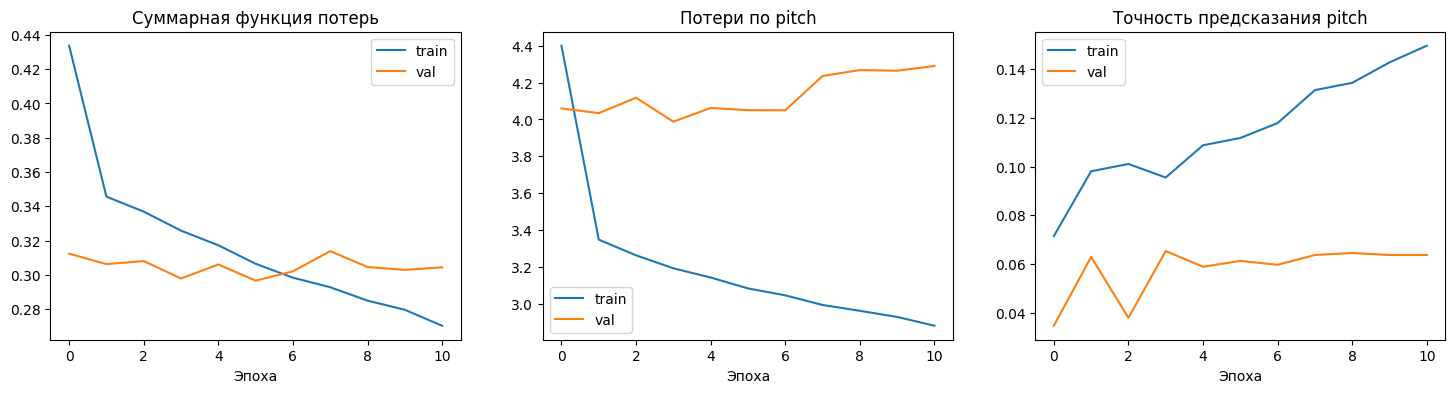

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('Суммарная функция потерь')
axes[1].plot(history.history['pitch_loss'], label='train')
axes[1].plot(history.history['val_pitch_loss'], label='val')
axes[1].set_title('Потери по pitch')
axes[2].plot(history.history['pitch_sparse_categorical_accuracy'], label='train')
axes[2].plot(history.history['val_pitch_sparse_categorical_accuracy'], label='val')
axes[2].set_title('Точность предсказания pitch')
for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.legend()
plt.show()

##генерация музыки

Как генерируется:

Берём стартовое окно из `seq_length` нот, модель предсказывает распределение для `pitch` и значения `step`, `duration`,`pitch` сэмплируется из распределения softmax с параметром температуры: логиты делятся на `temperature`. Маленькая температура даёт «безопасную», но однообразную мелодию, большая — более разнообразную, но хаотичную. Выбор ноты с максимальной вероятностью (argmax) приводит к зацикливанию, новая нота добавляется в конец окна, самая старая удаляется, и процесс повторяется.

In [16]:
def predict_next_note(notes: np.ndarray, model: tf.keras.Model,
                      temperature: float = 1.0):

    assert temperature > 0
    inputs = tf.expand_dims(notes, 0)
    predictions = model(inputs, training=False) #gо окну нот (pitch уже нормализован) генерирует одну ноту (pitch, step, duration)

    pitch_logits = predictions['pitch'] / temperature
    pitch = tf.random.categorical(pitch_logits, num_samples=1)
    pitch = int(tf.squeeze(pitch))
    step = max(0.0, float(tf.squeeze(predictions['step'])))
    duration = max(0.0, float(tf.squeeze(predictions['duration'])))
    return pitch, step, duration


def generate(model, seed_window: np.ndarray, num_predictions: int = 200,
             temperature: float = 1.0) -> pd.DataFrame:
    input_notes = seed_window.copy()
    generated, prev_start = [], 0.0
    for _ in range(num_predictions):
        pitch, step, duration = predict_next_note(input_notes, model, temperature)
        start = prev_start + step
        end = start + duration
        generated.append((pitch, step, duration, start, end))
        # ВАЖНО: pitch возвращаем во входное окно нормализованным
        new_note = np.array([[pitch / vocab_size, step, duration]], dtype=np.float32)
        input_notes = np.concatenate([input_notes[1:], new_note], axis=0)
        prev_start = start
    return pd.DataFrame(generated, columns=(*key_order, 'start', 'end'))

In [17]:
seed_window = X_val[np.random.randint(len(X_val))]
generated_notes = generate(model, seed_window, num_predictions=200, temperature=1.0)
generated_notes.head(10)

,pitch,step,duration,start,end
0,56,0.095245,0.404639,0.095245,0.499883
1,59,0.101792,0.462891,0.197036,0.659928
2,69,0.114927,0.497685,0.311964,0.809649
3,69,0.129191,0.511370,0.441154,0.952525
4,58,0.136922,0.511056,0.578076,1.089132
5,62,0.135562,0.503793,0.713638,1.217431
6,59,0.135200,0.492737,0.848837,1.341574
7,50,0.134250,0.490192,0.983087,1.473280
8,62,0.131815,0.495395,1.114902,1.610298
9,43,0.136765,0.500350,1.251668,1.752018


###как влияет температура

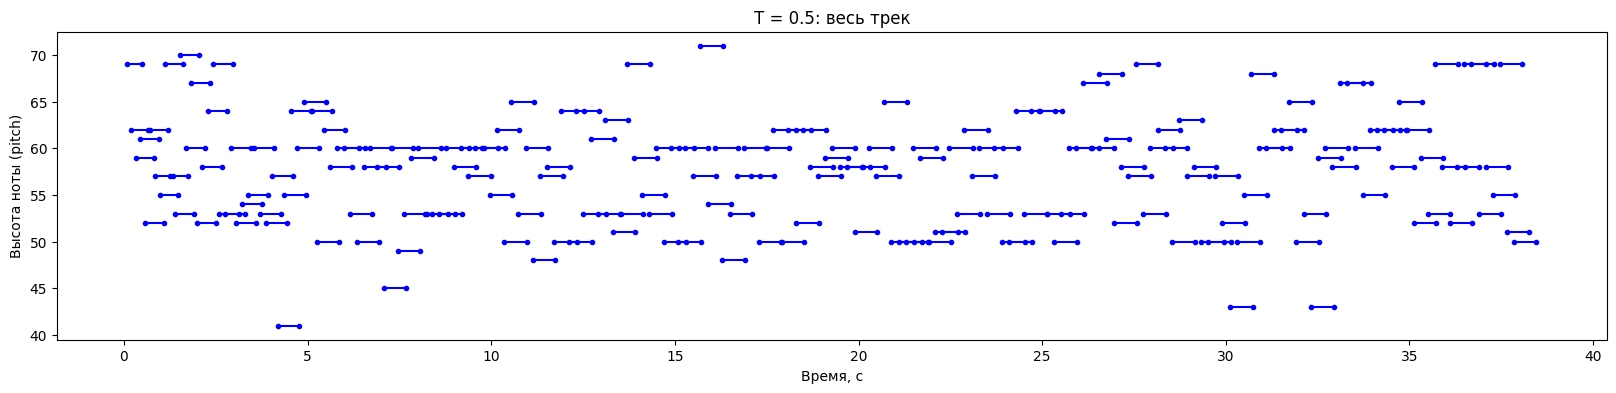

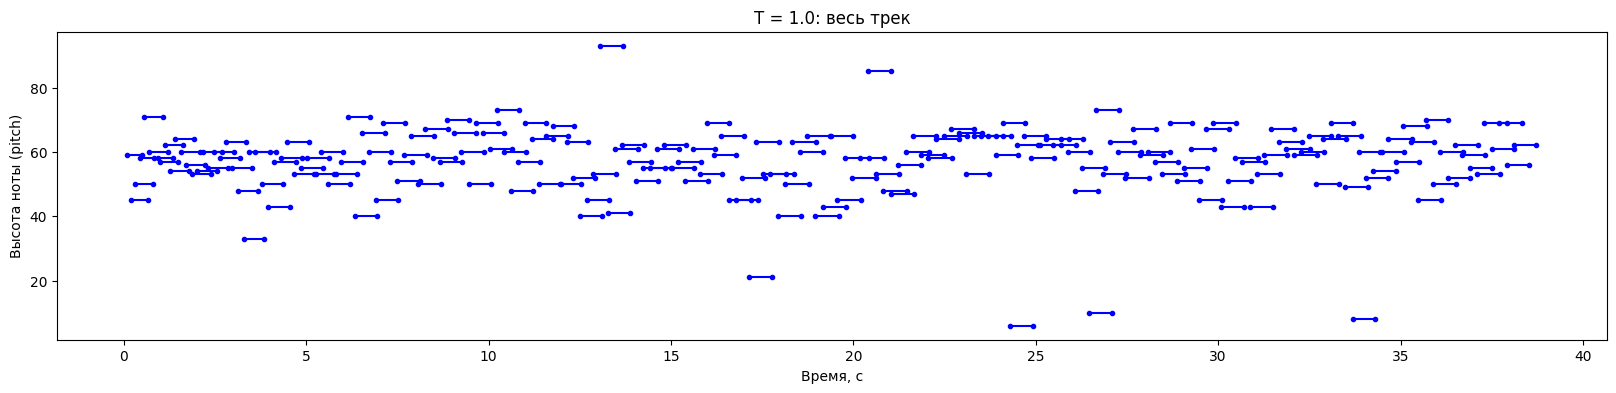

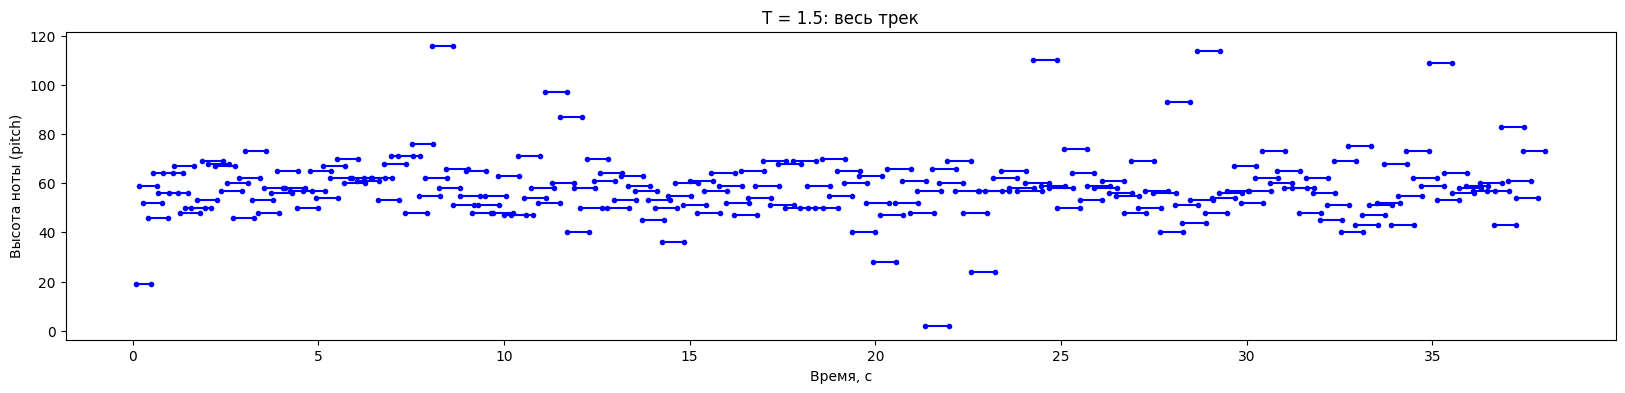

,T=0.5,T=1.0,T=1.5
уникальных pitch,25.000,37.000,46.000
средний pitch,57.495,57.100,58.320
"средний step, с",0.189,0.191,0.187
"средняя duration, с",0.605,0.609,0.599


In [18]:
temperatures = [0.5, 1.0, 1.5]
results = {}
for T in temperatures:
    results[T] = generate(model, seed_window, num_predictions=200, temperature=T)
    plot_piano_roll(results[T], title_prefix=f'T = {T}: ')

summary = pd.DataFrame({
    f'T={T}': {
        'уникальных pitch': df['pitch'].nunique(),
        'средний pitch': df['pitch'].mean(),
        'средний step, с': df['step'].mean(),
        'средняя duration, с': df['duration'].mean(),
    } for T, df in results.items()
}).round(3)
summary

### cохраняем результат

In [19]:
BEST_T = 1.0

out_pm = notes_to_midi(results[BEST_T], out_file='rock_generated.mid',
                       program=30, add_drums=True, bpm=120)
display_audio(out_pm, seconds=40)

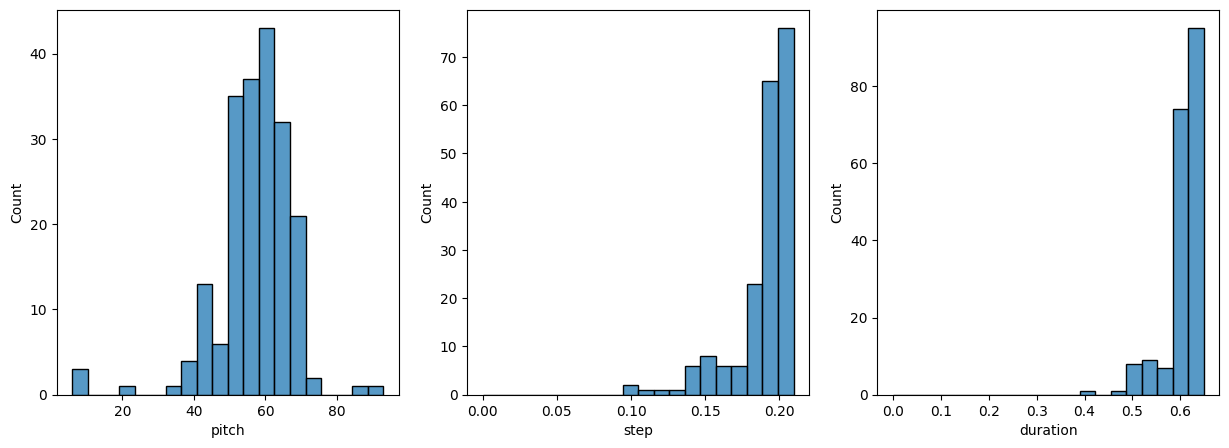

In [20]:
plot_distributions(results[BEST_T])

In [21]:
from google.colab import files
files.download('rock_generated.mid')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>